In [19]:
import pandas as pd
import numpy as np
from itertools import product
from scipy.stats import norm
from scipy.optimize import minimize
import matplotlib.pyplot as plt

## IMPORTATION ET NETTOYAGE DES DONNES

Les données ont été prétraitées avec les classes de preprocessing données par le tuteur. Nous partons donc ici des données trimestrialisées et homogéneisées

In [20]:
# Charger le fichier Excel
df = pd.read_csv("data\credit_ratings\sectors_quater.csv")

# Afficher les premières lignes
#df.head()

On mets certaines colonnes au bon formats et on fait un diagnostic r    pide pour s'assurer qu'on part avec de bonnes données

In [21]:
def clean_data_rating_corporate(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # 1) Dates
    df["rating_action_date"] = pd.to_datetime(df["rating_action_date"], errors="coerce")

    # year_month : souvent "YYYY-MM-01" en string -> datetime Month Start
    df["year_month"] = pd.to_datetime(df["year_month"], errors="coerce")

    # year_quater : souvent "YYYY-MM-01" en string -> datetime Month Start
    df["year_quarter"] = pd.to_datetime(df["year_quarter"], errors="coerce")


    # 2) Strings : trim
    for c in ["rating_agency_name", "rating", "legal_entity_identifier", "obligor_name", "pays", "nace"]:
        df[c] = df[c].astype("string").str.strip()


    # 4) Nettoyage secteur (NACE)
    # (Tu peux adapter selon ton codage : lettres, divisions, etc.)
    df["nace"] = df["nace"].str.upper()

    # 5) Nettoyage rating
    df["rating"] = df["rating"].str.upper()

    return df


def quick_diagnostics(df: pd.DataFrame):
    print("---- DIAGNOSTICS ----")
    print("Nb lignes:", len(df))
    print("Nb entreprises (obligor_name):", df["obligor_name"].nunique())
    print("Nb agences:", df["rating_agency_name"].nunique())
    print("Nb secteurs (nace):", df["nace"].nunique())
    print("Période year_month:", df["year_month"].min(), "->", df["year_month"].max())

    print("\nTop agences:")
    print(df["rating_agency_name"].value_counts().head(10))

    print("\nTop ratings:")
    print(df["rating"].value_counts().head(15))

    print("\nTop secteurs (nace):")
    print(df["nace"].value_counts().head(15))

df=clean_data_rating_corporate(df)
quick_diagnostics(df)

---- DIAGNOSTICS ----
Nb lignes: 179452
Nb entreprises (obligor_name): 10315
Nb agences: 5
Nb secteurs (nace): 18
Période year_month: 2010-07-01 00:00:00 -> 2023-06-01 00:00:00

Top agences:
rating_agency_name
Standard & Poor's Ratings Services    75834
Egan-Jones Ratings Company            51647
Moody's Investors Service             20419
Japan Credit Rating Agency,Ltd.       17994
Fitch Ratings                         13558
Name: count, dtype: Int64

Top ratings:
rating
BBB    46581
B      45296
A      36357
BB     35061
AAA     9495
C       6662
Name: count, dtype: Int64

Top secteurs (nace):
nace
C5    21796
RU    20063
KZ    19998
C3    18309
JZ    15628
LZ    13557
BZ    13410
HZ    11513
C1     8483
GZ     7864
OQ     7462
CH     4526
C2     4385
C4     3312
IZ     3118
Name: count, dtype: Int64


## Regroupement sectoriel

In [22]:

import pandas as pd
import numpy as np

# 1) Mapping économique (à adapter si C1..C5 sont connus chez toi)
ECON_GROUP_MAP = {
    # Primaires / énergie
    "AZ": "extraction_primaire",
    "BZ": "extraction_primaire",  # si présent

    # Industrie / construction / immobilier

    "FZ": "construction_immo",
    "LZ": "construction_immo",

    # Transport / info
    "JZ": "info-com",

    # Services marchands
    "GZ": "services",
    "IZ": "services",
    "HZ": "services",

    # Finance
    "KZ": "finance",

    # Non-marchands / public
    "OQ": "public",
    "RU": "public",

    # Services pro (souvent très cycliques mais “services”)
    "MN": "services_pro",

    # Cas C1..C5 (à défaut)
    "C1": "industrie",
    "C2": "industrie",
    "C3": "industrie",
    "C4": "industrie",
    "C5": "industrie",
    "CH": "industrie",  
}


def add_econ_group(df_Z, sector_col="sector"):
    df = df_Z.copy()
    df["sector"] = df[sector_col].map(ECON_GROUP_MAP).fillna("Autres")
    return df


df_clean=add_econ_group(df, sector_col="nace")

## Regroupement par zone géographique

In [23]:
eu=['GB', 'DE', 'SE', 'CH', 'RU', 'ES', 'FR', 'NO', 'NL', 
 'IE', 'BE', 'LU', 'IT', 'DK', 'GI', 'JE', 'CY', 
 'AT', 'PT', 'RO', 'TR', 'FI', 'IS', 'GE', 'GG', 
 'IM', 'BG', 'PL', 'GL', 'CZ']
df_eu=df_clean[df_clean['pays'].isin(eu)]
am=['US', 'CA', 'BR', 'KY', 'CO', 'AR', 'CL', 'BM', 
 'MX', 'PA', 'LC', 'VG', 'PE', 'BS', 'PY', 
 'TT', 'CW']
df_am=df_clean[df_clean['pays'].isin(am)]
autre=['IN', 'ID', 'TW', 'AE', 'NZ', 'VN', 
 'CN', 'HK', 'PH', 'ZA', 'IL', 'MH', 
 'NG', 'OM', 'SG', 'MY', 'MU', 'LK', 'SA']
df_autre=df_clean[df_clean['pays'].isin(autre)]
jp=["JP"]
df_jp=df_clean[df_clean['pays'].isin(jp)]

## MATRICE DE TRANSITION PAR SECTEUR

In [24]:
# Nombre total de transitions pour un secteur donné sur toute la période

def nb_transitions(data, sector_value="finance"):
    data_sector = data[data["sector"] == sector_value]

    transition_counts = (
        data_sector
        .groupby(["rating", "next_rating"])
        .size()
        .reset_index(name="n")
    )

    transition_matrix = transition_counts.pivot_table(
        index="rating",
        columns="next_rating",
        values="n",
        fill_value=0
    )

    ordre_indices = ["AAA", "A", "BBB", "BB", "B", "C"]
    ordre_colonnes = ["AAA", "A", "BBB", "BB", "B", "C", "D"]

    return transition_matrix.reindex(
        index=ordre_indices,
        columns=ordre_colonnes
    ).fillna(0)

In [25]:
transition_matrix_finance=nb_transitions(df_clean, sector_value="finance")

In [26]:
# Calcul de la matrice de transition TTC (Transition To Transition) pour un secteur donné sur toute la période
def calculate_migration_ttc(df_clean,sector="finance"):
    transition_matrix = nb_transitions(df_clean, sector_value=sector)
    row_sums = transition_matrix.sum(axis=1)
    migration_ttc = transition_matrix.div(row_sums, axis=0)

    return migration_ttc

migration_ttc_finance=calculate_migration_ttc(df_clean=df_clean, sector="finance")

In [27]:
   
# Creation d'un dataframe complet des transitions observées par secteur et par période (year_quarter) avec les probabilités de transition
from itertools import product
import pandas as pd

def create_complete_quaterly_migration_counts_by_sector(df, sector_col="sector"):
    ratings = ["AAA", "A", "BBB", "BB", "B", "C", "D"]

    # counts observés
    migrations_count = (
        df.groupby(["year_quarter", sector_col, "rating", "next_rating"])
          .size()
          .reset_index(name="count")
    )

    unique_periods = migrations_count["year_quarter"].unique()
    unique_sectors = migrations_count[sector_col].unique()

    # toutes les combinaisons (period x sector x rating x next_rating)
    all_combinations = pd.DataFrame(
        list(product(unique_periods, unique_sectors, ratings, ratings)),
        columns=["year_quarter", sector_col, "rating", "next_rating"]
    )

    migrations_complete = all_combinations.merge(
        migrations_count,
        on=["year_quarter", sector_col, "rating", "next_rating"],
        how="left"
    )

    # on ne modélise pas les transitions à partir de D
    migrations_complete = migrations_complete[migrations_complete["rating"] != "D"].copy()

    # remplissage + proba
    migrations_complete["count"] = migrations_complete["count"].fillna(0).astype(int)

    migrations_complete["total_count"] = (
        migrations_complete.groupby(["year_quarter", sector_col, "rating"])["count"]
        .transform("sum")
        .fillna(0)
        .astype(int)
    )

    migrations_complete["transition_prob"] = (
        migrations_complete["count"] / migrations_complete["total_count"]
    ).fillna(0)

    return migrations_complete

migrations_count_complete = create_complete_quaterly_migration_counts_by_sector(df_clean)

In [28]:
# Création de la matrice de transition PIT (Point In Time) par secteur et par période (year_quarter)
def create_matrice_PIT_by_sector(migrations_complete, sector_col="sector"):
    return migrations_complete.pivot_table(
        index=["year_quarter", sector_col, "rating"],
        columns="next_rating",
        values="transition_prob",
        fill_value=0,
    )
matrice_pit=create_matrice_PIT_by_sector(migrations_count_complete)

## BARRIERES DE TRANSITION

In [29]:
# Calcul de la matrice de barrières à partir de la matrice de transition TTC pour un secteur donné
def calculate_barrier_matrix(df_clean,sector="finance"):
    ttc_matrix=calculate_migration_ttc(df_clean, sector=sector)
    barrier_matrix = np.zeros_like(ttc_matrix, dtype=float)
    for idx, (i, row) in enumerate(ttc_matrix.iterrows()):
        cumulative_sum = 0
        for j in reversed(range(len(row))):
            cumulative_sum += row.iloc[j]
            barrier_matrix[idx, j] = norm.ppf(cumulative_sum)
    barrier_matrix_df = pd.DataFrame(barrier_matrix, index=ttc_matrix.index, columns=ttc_matrix.columns)
    return barrier_matrix_df

def calculate_rho(pd_series):
    value = (1 - np.exp(-50 * pd_series)) / (1 - np.exp(-50))
    return 0.12 * value + 0.24 * (1 - value)

In [30]:
import numpy as np
import pandas as pd
from scipy.stats import norm

def calculate_barrier_matrix(df_clean, sector="finance"):
    ttc_matrix = calculate_migration_ttc(df_clean, sector=sector)
    barrier_matrix = np.zeros_like(ttc_matrix, dtype=float)
    for idx, (i, row) in enumerate(ttc_matrix.iterrows()):
        cumulative_sum = 0
        for j in reversed(range(len(row))):
            cumulative_sum += row.iloc[j]
            barrier_matrix[idx, j] = norm.ppf(cumulative_sum)
    barrier_matrix_df = pd.DataFrame(
        barrier_matrix,
        index=ttc_matrix.index,
        columns=ttc_matrix.columns
    )
    return barrier_matrix_df


def calculate_barriers_all_sectors(
    df_clean: pd.DataFrame,
    sector_col: str = "sector",  
    sectors: list | None = None
) -> pd.DataFrame:
    """
    Calcule les barrières pour tous les secteurs en gardant la convention:
      index = rating (t-1), columns = next_rating (t)

    Retour:
      DataFrame long avec colonnes:
        ['sector','rating','next_rating','barrier']
    """
    if sectors is None:
        if sector_col not in df_clean.columns:
            raise ValueError(f"'{sector_col}' absent du df_clean. Donne sector_col=... ou sectors=[...].")
        sectors = sorted(df_clean[sector_col].dropna().unique().tolist())

    all_long = []

    for s in sectors:
        try:
            bmat = calculate_barrier_matrix(df_clean, sector=s)
        except Exception as e:
            print(f"[WARN] Secteur '{s}' ignoré (erreur): {e}")
            continue

        
        bmat = bmat.copy()
        bmat.index.name = "rating"
        bmat.columns.name = "next_rating"

        blong = (
            bmat
            .reset_index()                      
            .melt(
                id_vars="rating",
                var_name="next_rating",
                value_name="barrier"
            )
        )
        blong.insert(0, "sector", s)
        all_long.append(blong)

    if not all_long:
        return pd.DataFrame(columns=["sector","rating","next_rating","barrier"])

    barriers_all = pd.concat(all_long, ignore_index=True)


    return barriers_all



barriers_all = calculate_barriers_all_sectors(df_clean=df_clean, sector_col="sector") 
barriers_all
barrier_matrix_df = calculate_barrier_matrix(df_clean=df_clean,sector="finance")
rho_finance=calculate_rho(migration_ttc_finance["D"])
barrier_matrix_df

next_rating,AAA,A,BBB,BB,B,C,D
rating,,,,,,,
AAA,inf,-1.274432,-2.636841,-2.805688,-2.805688,-inf,-inf
A,inf,2.009321,-1.542466,-2.881663,-3.405966,-3.590810,-inf
BBB,inf,3.118228,1.418601,-1.877163,-2.778666,-3.317057,-3.506023
BB,inf,inf,2.827795,1.504027,-1.376292,-2.491464,-inf
B,inf,inf,inf,2.698544,1.730325,-1.405844,-2.786645
C,8.209536,8.209536,8.209536,2.858587,1.883930,0.671146,-1.853367


In [31]:
# Calcul des probabilités de transition PIT à partir de la matrice de barrières, du facteur systémique z_t et du rho
def calculate_pit_probabilities(z_t, barrier_matrix, rho):
    ratings = barrier_matrix.index
    next_ratings = barrier_matrix.columns
    pit_matrix = pd.DataFrame(index=ratings, columns=next_ratings, dtype=float)

    for i, rating in enumerate(ratings):
        rho_i = rho[rating]
        for j, next_rating in enumerate(next_ratings):
            if j == 0:
                b_next = barrier_matrix.loc[rating, next_ratings[j + 1]]
                numerator = b_next - np.sqrt(rho_i) * z_t
                probability = 1 - norm.cdf(numerator / np.sqrt(1 - rho_i))
            elif j == len(next_ratings) - 1:
                b = barrier_matrix.loc[rating, next_rating]
                probability = norm.cdf((b - np.sqrt(rho_i) * z_t) / np.sqrt(1 - rho_i))
            else:
                b = barrier_matrix.loc[rating, next_rating]
                b_next = barrier_matrix.loc[rating, next_ratings[j + 1]]
                term1 = norm.cdf((b - np.sqrt(rho_i) * z_t) / np.sqrt(1 - rho_i))
                term2 = norm.cdf((b_next - np.sqrt(rho_i) * z_t) / np.sqrt(1 - rho_i))
                probability = term1 - term2
            pit_matrix.loc[rating, next_rating] = probability
    return pit_matrix

In [32]:
# Calcul de la Mean Squared Error (MSE) globale et par rating->next_rating entre les probabilités de transition observées et recalculées
def mse(probability_migrations):
    """Calcule la Mean Squared Error globale et par rating->next_rating."""
    df = probability_migrations.copy()
    df["squared_error"] = (df["observed"] - df["recalculated"])**2

    # MSE global
    mse_global = df["squared_error"].mean()

    # MSE par rating -> next_rating
    mse_matrix = df.groupby(["rating", "next_rating"])["squared_error"].mean().unstack().fillna(0)

    return mse_global, mse_matrix

## EXTRACTION DU FACTEUR SYSTEMIQUE

In [33]:
# Optimisation du facteur systémique z_t par secteur et par période (year_quarter) pour minimiser la MSE entre les probabilités de transition observées et recalculées
import numpy as np
import pandas as pd
from scipy.optimize import minimize

def optimize_by_sector(df_clean, date_level="year_quarter", sector_value="finance", sector_level="sector"):
    zt = {}
    all_probs = []

    migrations_complete = create_complete_quaterly_migration_counts_by_sector(df_clean)
    migration_pit = create_matrice_PIT_by_sector(migrations_complete, sector_col=sector_level)

    # --- filtre sur le secteur demandé si le niveau existe dans l'index ---
    if sector_level in migration_pit.index.names:
        try:
            migration_pit_sector = migration_pit.xs(sector_value, level=sector_level)
        except KeyError:
            # secteur absent
            zt_series = pd.Series(dtype=float, name="z_t")
            probability_migrations = pd.DataFrame()
            return zt_series, probability_migrations, np.nan, None
    else:
        migration_pit_sector = migration_pit

    # Paramètres cohérents avec le secteur calibré
    barrier_matrix = calculate_barrier_matrix(df_clean=df_clean, sector=sector_value)
    rho = calculate_rho(calculate_migration_ttc(df_clean=df_clean, sector=sector_value)["D"])

    dates = migration_pit_sector.index.get_level_values(date_level).unique()

    for t in dates:
        # Matrice PIT observée pour la date t (déjà filtrée au secteur)
        try:
            pit_obs = migration_pit_sector.xs(t, level=date_level).sort_index()
        except KeyError:
            continue

        if pit_obs is None or pit_obs.size == 0:
            continue

        def loss(z):
            pit_th = calculate_pit_probabilities(float(z[0]), barrier_matrix, rho).sort_index()

            # Aligne index ET colonnes pour éviter toute incohérence
            a_obs, a_th = pit_obs.align(pit_th, join="inner", axis=None)

            diff = a_obs.values - a_th.values
            return np.nansum(diff ** 2)

        res = minimize(loss, x0=np.array([0.0]), bounds=[(-5, 5)], method="L-BFGS-B")
        z_hat = float(res.x[0])

        # Stocke zt avec un index (sector, date) directement
        zt[(sector_value, t)] = z_hat

        pit_th_hat = calculate_pit_probabilities(z_hat, barrier_matrix, rho).sort_index()

        probs_df = pd.concat(
            [
                pit_obs.stack().rename("observed"),
                pit_th_hat.stack().rename("recalculated"),
            ],
            axis=1,
            join="inner",
        ).reset_index()

        probs_df[date_level] = t
        probs_df[sector_level] = sector_value
        all_probs.append(probs_df)

    # Série des Zt par (sector, date)
    zt_series = pd.Series(zt, name="z_t")
    if len(zt_series) > 0:
        zt_series.index = pd.MultiIndex.from_tuples(
            zt_series.index, names=[sector_level, date_level]
        )
        zt_series = zt_series.sort_index()
    else:
        zt_series = pd.Series(dtype=float, name="z_t")
        zt_series.index = pd.MultiIndex.from_tuples([], names=[sector_level, date_level])

    # Tableau des proba observées vs recalculées
    probability_migrations = pd.concat(all_probs, ignore_index=True) if all_probs else pd.DataFrame()
    if not probability_migrations.empty:
        probability_migrations = probability_migrations.set_index(
            [date_level, sector_level, "rating", "next_rating"]
        ).sort_index()
        mse_global, mse_matrix = mse(probability_migrations)
    else:
        mse_global, mse_matrix = np.nan, None

    return zt_series, probability_migrations, mse_global, mse_matrix, rho

zt_sector, probs_sector, mse_global_sector, mse_matrix_sector, rho_sector = optimize_by_sector(df_clean=df_clean, sector_value="industrie")

In [34]:
import os
import numpy as np
import pandas as pd

SECTORS_DEFAULT = [
    'public', 'info-com', 'industrie', 'finance', 'services',
    'services_pro', 'construction_immo', 'extraction_primaire'
]

def extract_zt_all_sectors_to_csv(
    df_clean: pd.DataFrame,
    sectors=SECTORS_DEFAULT,
    date_level: str = "year_quarter",
    sector_level: str = "sector",
    out_dir: str = ".",
    zt_filename: str = "zt_by_sector.csv",
    probs_filename: str = "pit_probs_observed_vs_recalculated.csv",
    mse_filename: str = "mse_by_sector.csv",
    save_probs: bool = True,
    save_mse: bool = True,
):
    """
    Lance optimize_by_sector pour chaque secteur, concatène les résultats,
    et sauvegarde en CSV:
      - zt_by_sector.csv : z_t par (sector, year_quarter)
      - pit_probs_observed_vs_recalculated.csv (optionnel)
      - mse_by_sector.csv (optionnel)
    """
    os.makedirs(out_dir, exist_ok=True)

    zt_list = []
    probs_list = []
    mse_rows = []
    rho_list = []

    for sec in sectors:
        zt_series, prob_df, mse_global, mse_matrix, rho = optimize_by_sector(
            df_clean,
            date_level=date_level,
            sector_value=sec,
            sector_level=sector_level
        )
        
        rho_list.append({"sector": sec, "rho": rho})

        # --- ZT ---
        if zt_series is not None and len(zt_series) > 0:
            zt_list.append(zt_series.rename("z_t").to_frame())
        else:
            # garde trace même si vide
            mse_rows.append({"sector": sec, "mse_global": np.nan, "n_zt": 0})
            continue

        # --- Probas obs vs recalc ---
        if save_probs and isinstance(prob_df, pd.DataFrame) and not prob_df.empty:
            # remet en colonnes pour écrire facilement en CSV
            probs_list.append(prob_df.reset_index())

        # --- MSE ---
        if save_mse:
            mse_rows.append({
                "sector": sec,
                "mse_global": float(mse_global) if mse_global is not None else np.nan,
                "n_zt": int(len(zt_series))
            })

    # ============ EXPORT ZT ============
    if zt_list:
        zt_all = pd.concat(zt_list).reset_index()
        zt_all.columns = [sector_level, date_level, "z_t"]
        zt_all = zt_all.sort_values([sector_level, date_level])

        zt_path = os.path.join(out_dir, zt_filename)
        zt_all.to_csv(zt_path, index=False)
    else:
        zt_all = pd.DataFrame(columns=[sector_level, date_level, "z_t"])
        zt_path = os.path.join(out_dir, zt_filename)
        zt_all.to_csv(zt_path, index=False)

    # ============ EXPORT PROBS (optionnel) ============
    probs_path = None
    if save_probs:
        probs_path = os.path.join(out_dir, probs_filename)
        if probs_list:
            probs_all = pd.concat(probs_list, ignore_index=True)
            probs_all.to_csv(probs_path, index=False)
        else:
            pd.DataFrame().to_csv(probs_path, index=False)

    # ============ EXPORT MSE (optionnel) ============
    mse_path = None
    if save_mse:
        mse_path = os.path.join(out_dir, mse_filename)
        mse_df = pd.DataFrame(mse_rows).sort_values("sector")
        mse_df.to_csv(mse_path, index=False)

    rho_df = pd.DataFrame(rho_list)
    rho_df.to_csv(os.path.join(out_dir, "rho_by_sector.csv"), index=False)

    return {
        "zt": zt_all,
        "zt_csv": zt_path,
        "probs_csv": probs_path,
        "mse_csv": mse_path,
        "rho_csv": os.path.join(out_dir, "rho_by_sector.csv"),
    }

In [35]:
"""
result = extract_zt_all_sectors_to_csv(
    df_clean=df_jp,
    out_dir="zt_jp",
    save_probs=True,   
    save_mse=True
)

print("ZT saved to:", result["zt_csv"])
print("Probs saved to:", result["probs_csv"])
print("MSE saved to:", result["mse_csv"])
print("Rho saved to:", result["rho_csv"])

"""

'\nresult = extract_zt_all_sectors_to_csv(\n    df_clean=df_jp,\n    out_dir="zt_jp",\n    save_probs=True,   \n    save_mse=True\n)\n\nprint("ZT saved to:", result["zt_csv"])\nprint("Probs saved to:", result["probs_csv"])\nprint("MSE saved to:", result["mse_csv"])\nprint("Rho saved to:", result["rho_csv"])\n\n'

## TEST DE KOLMOGOROV SMIRNOV POUR LA NORMALITE DU FACTEUR SYSTEMIQUE

In [36]:

EXPORT_DIR = "data/facteurs_systemiq"
Z_hat_gen = pd.read_csv(f"{EXPORT_DIR}/zt_am/zt_by_sector.csv")


In [37]:
import numpy as np
from scipy import stats

def ks_test_normality(z):
    """
    Test de Kolmogorov-Smirnov pour normalité
    """

    # estimation paramètres
    mu = np.mean(z)
    sigma = np.std(z, ddof=1)

    # test KS
    ks_stat, p_value = stats.kstest(z, 'norm', args=(mu, sigma))

    print("Test KS pour normalité")
    print(f"Statistique KS : {ks_stat:.4f}")
    print(f"p-value        : {p_value:.4f}")
    print(f"μ estimé       : {mu:.4f}")
    print(f"σ estimé       : {sigma:.4f}")

    if p_value < 0.05:
        print("→ Rejet de H0 : z_t ne suit pas une loi normale")
    else:
        print("→ Impossible de rejeter H0 : normalité plausible")

    return ks_stat, p_value

zt_finance = zt_sector.copy()
ks_test_normality(zt_finance)

Test KS pour normalité
Statistique KS : 0.0755
p-value        : 0.9065
μ estimé       : 0.1138
σ estimé       : 0.8873
→ Impossible de rejeter H0 : normalité plausible


(np.float64(0.07549593704909574), np.float64(0.9065361870076492))

In [38]:
import numpy as np
import pandas as pd
from scipy import stats

def ks_test_normality(z):
    """
    Test de Kolmogorov-Smirnov pour normalité
    """
    mu = np.mean(z)
    sigma = np.std(z, ddof=1)

    ks_stat, p_value = stats.kstest(z, 'norm', args=(mu, sigma))

    return ks_stat, p_value, mu, sigma


def ks_test_by_sector(zt_sector, sectors, alpha=0.05):
    """
    Applique le test KS de normalité à une liste de secteurs.

    Parameters
    ----------
    zt_sector : pandas Series/DataFrame
        Données indexées avec un MultiIndex contenant 'sector'
    sectors : list
        Liste des secteurs à tester
    alpha : float
        Seuil de significativité
    plot : bool
        Si True, affiche l'histogramme

    Returns
    -------
    pandas.DataFrame
        Tableau récapitulatif des résultats
    """

    results = []

    for sector in sectors:
        try:
            z_values =Z_hat_gen[Z_hat_gen["sector"] == sector]["z_t"]

            ks_stat, p_value, mu, sigma = ks_test_normality(z_values)

            decision = "Rejet H0 (non normal)" if p_value < alpha else "Normalité plausible"

            results.append({
                "sector": sector,
                "n_obs": len(z_values),
                "ks_stat": ks_stat,
                "p_value": p_value,
                "mu_hat": mu,
                "sigma_hat": sigma,
                "decision": decision
            })

        except KeyError:
            print(f"Secteur {sector} non trouvé")

    return pd.DataFrame(results).set_index("sector")

In [39]:
sectors_list = ["finance", "info-com", "extraction_primaire", "industrie", "services", "services_pro", "construction_immo", "public"]

ks_results = ks_test_by_sector(zt_sector, sectors_list)

print(ks_results)

                     n_obs   ks_stat   p_value    mu_hat  sigma_hat  \
sector                                                                
finance                 51  0.107379  0.562273 -0.334116   0.994285   
info-com                51  0.084045  0.834429 -0.243640   1.035572   
extraction_primaire     51  0.079774  0.875993  0.036028   1.136464   
industrie               51  0.133668  0.294940 -0.051420   0.953225   
services                51  0.097059  0.686262 -0.274470   1.007293   
services_pro            51  0.146960  0.199879 -0.559729   1.362247   
construction_immo       51  0.155461  0.152726  0.018689   1.087643   
public                  51  0.065780  0.969672 -0.232340   0.943603   

                                decision  
sector                                    
finance              Normalité plausible  
info-com             Normalité plausible  
extraction_primaire  Normalité plausible  
industrie            Normalité plausible  
services             Normalité 

## REPRESENTATIONS GRAPHIQUES

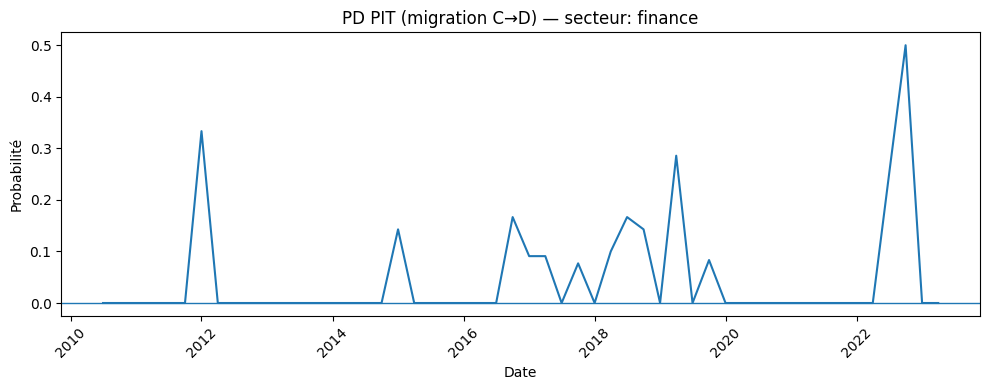

In [40]:
def plot_pd_pit_over_time(matrice_pit, sector, rating="BBB", default_col="D"):
    df_sec = matrice_pit.xs((sector, rating), level=("sector", "rating"))
    # df_sec index = year_quarter ; colonnes = next_rating
    if default_col not in df_sec.columns:
        raise ValueError(f"Colonne défaut '{default_col}' absente. Colonnes dispo: {list(df_sec.columns)}")

    s_pd = df_sec[default_col].sort_index()

    plt.figure(figsize=(10, 4))
    plt.plot(s_pd.index, s_pd.values)
    plt.axhline(0, linewidth=1)
    plt.title(f"PD PIT (migration {rating}→{default_col}) — secteur: {sector}")
    plt.xlabel("Date")
    plt.ylabel("Probabilité")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Exemple
plot_pd_pit_over_time(matrice_pit, sector="finance", rating="C")

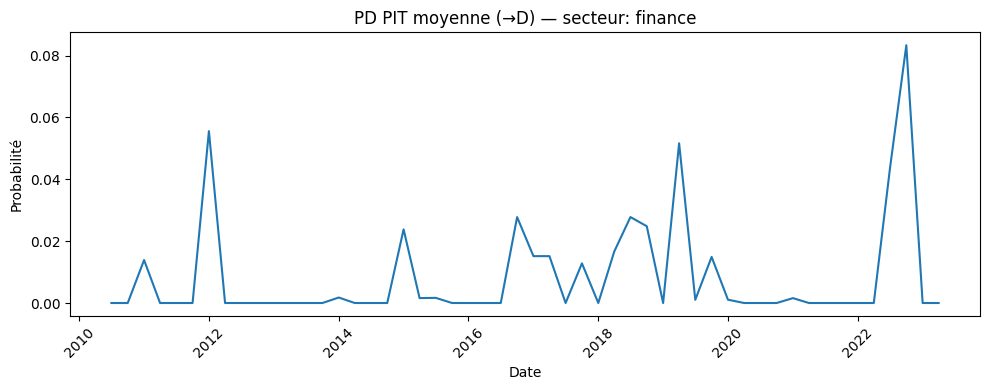

In [41]:
def plot_pd_pit_sector_average(matrice_pit, sector, default_col="D"):
    df_sec = matrice_pit.xs(sector, level="sector")  # index = (year_quarter, rating)
    if default_col not in df_sec.columns:
        raise ValueError(f"Colonne défaut '{default_col}' absente.")
    s = df_sec[default_col].groupby(level="year_quarter").mean().sort_index()

    plt.figure(figsize=(10, 4))
    plt.plot(s.index, s.values)
    plt.title(f"PD PIT moyenne (→{default_col}) — secteur: {sector}")
    plt.xlabel("Date")
    plt.ylabel("Probabilité")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Exemple
plot_pd_pit_sector_average(matrice_pit, "finance")

In [42]:

def plot_transitions(probability_migrations, pairs):
    """
    Trace les courbes observed vs recalculated pour une ou plusieurs paires (rating, next_rating).

    Args:
        pairs (list of [rating, next_rating]): liste de couples.
                                            Exemple: [["BBB","BB"], ["A","BBB"]]
    """
    if probability_migrations is None:
        raise ValueError("Les probabilités n'ont pas encore été calculées. Lancez optimize() d'abord.")

    import matplotlib.pyplot as plt
    from itertools import cycle

    plt.figure(figsize=(10, 5))
    colors = cycle(plt.cm.tab10.colors)  # palette cyclique pour les couleurs

    for rating, next_rating in pairs:
        color = next(colors)
        subset = probability_migrations.xs(
            (rating, next_rating), level=("rating", "next_rating")
        )
        plt.plot(subset.index, subset["observed"], label=f"Observed {rating}->{next_rating}", color=color)
        plt.plot(subset.index, subset["recalculated"], linestyle="--", label=f"Recalculated {rating}->{next_rating}", color=color)

    plt.title("Probabilités Observed vs Recalculated")
    plt.xlabel("Date")
    plt.ylabel("Transition Probability")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


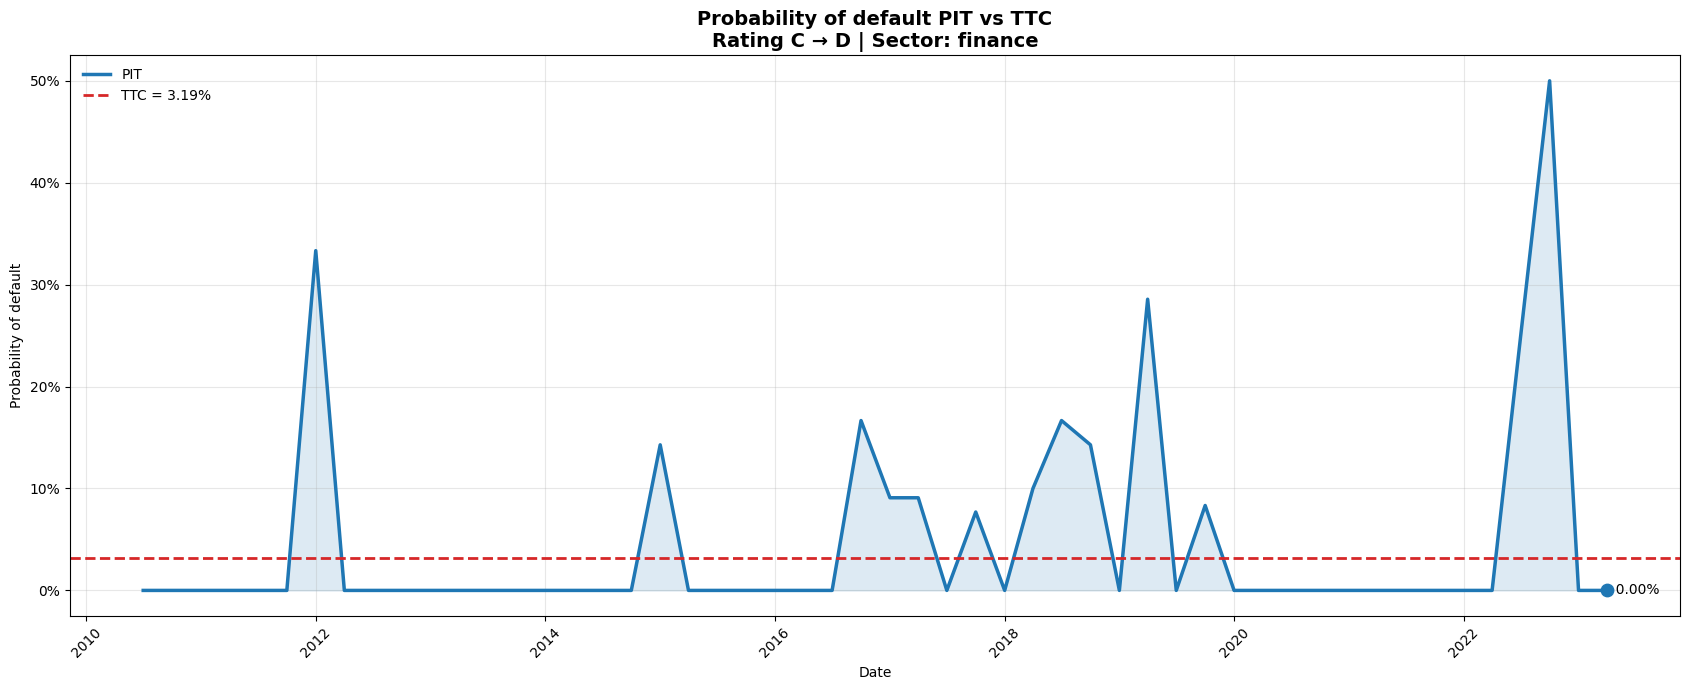

In [56]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

def plot_pit_vs_ttc_default(matrice_pit, migration_ttc, sector, rating="BBB", default_col="D"):
    df_sec = matrice_pit.xs((sector, rating), level=("sector", "rating"))
    s_pit = df_sec[default_col].sort_index()

    p_ttc = float(migration_ttc.loc[rating, default_col])

    plt.figure(figsize=(17, 7))

    # --- PIT line
    plt.plot(
        s_pit.index,
        s_pit.values,
        label="PIT",
        linewidth=2.5,
        color="#1f77b4"
    )

    # --- Area under PIT
    plt.fill_between(
        s_pit.index,
        s_pit.values,
        alpha=0.15,
        color="#1f77b4"
    )

    # --- TTC horizontal line
    plt.axhline(
        p_ttc,
        linestyle="--",
        linewidth=2,
        color="#d62728",
        label=f"TTC = {p_ttc:.2%}"
    )

    # --- Highlight last point
    plt.scatter(
        s_pit.index[-1],
        s_pit.values[-1],
        color="#1f77b4",
        s=80,
        zorder=3
    )

    # --- Annotation last value
    plt.text(
        s_pit.index[-1],
        s_pit.values[-1],
        f"  {s_pit.values[-1]:.2%}",
        va="center",
        fontsize=10
    )

    # --- Title
    plt.title(
        f"Probability of default PIT vs TTC\nRating {rating} → {default_col} | Sector: {sector}",
        fontsize=14,
        fontweight="bold"
    )

    # --- Axes
    plt.xlabel("Date")
    plt.ylabel("Probability of default")

    # Format en %
    plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

    # --- Grid (léger)
    plt.grid(alpha=0.3)

    # --- Legend propre
    plt.legend(frameon=False)

    # --- Rotation dates
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()
# Exemple
plot_pit_vs_ttc_default(matrice_pit, migration_ttc_finance, "finance", rating="C")

In [44]:
migration_ttc_finance

next_rating,AAA,A,BBB,BB,B,C,D
rating,,,,,,,
AAA,0.898745,0.097071,0.001674,0.000000,0.002510,0.000000,0.000000
A,0.022252,0.916268,0.059502,0.001648,0.000165,0.000165,0.000000
BBB,0.000910,0.077098,0.891744,0.027519,0.002274,0.000227,0.000227
BB,0.000000,0.002343,0.063944,0.849347,0.078005,0.006361,0.000000
B,0.000000,0.000000,0.003482,0.038304,0.878329,0.077222,0.002663
C,0.000000,0.000000,0.002128,0.027660,0.221277,0.717021,0.031915


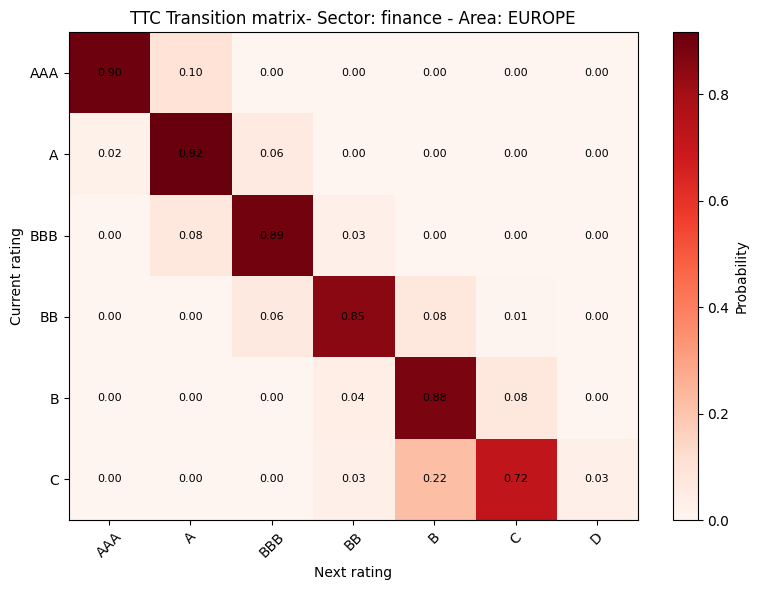

In [45]:
def plot_ttc_heatmap(migration_ttc, 
                     title="TTC Transition matrix- Sector: finance - Area: EUROPE",
                     cmap="viridis"):   # colormap par défaut

    M = migration_ttc.values

    plt.figure(figsize=(8, 6))
    plt.imshow(M, aspect="auto", cmap=cmap)
    plt.title(title)
    plt.xlabel("Next rating")
    plt.ylabel("Current rating")
    plt.xticks(range(len(migration_ttc.columns)), migration_ttc.columns, rotation=45)
    plt.yticks(range(len(migration_ttc.index)), migration_ttc.index)

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8)

    plt.colorbar(label="Probability")
    plt.tight_layout()
    plt.show()

plot_ttc_heatmap(migration_ttc_finance, cmap="Reds")

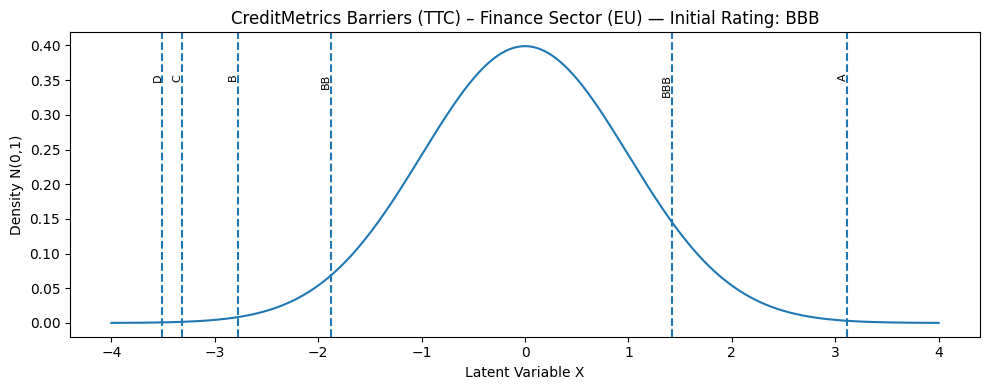

In [46]:
def plot_barriers_normal(barrier_matrix_df, rating="BBB"):
    b = barrier_matrix_df.loc[rating].copy()

    # On ne garde que les valeurs finies et on les trie
    b = b[np.isfinite(b)].sort_values()

    x = np.linspace(-4, 4, 800)
    y = norm.pdf(x)

    plt.figure(figsize=(10, 4))
    plt.plot(x, y)
    for k, val in enumerate(b.values):
        plt.axvline(val, linestyle="--")
        plt.text(val, y.max()*0.9, b.index[k], rotation=90, va="top", ha="right", fontsize=8)

    plt.title(f"CreditMetrics Barriers (TTC) – Finance Sector (EU) — Initial Rating: {rating}")
    plt.xlabel("Latent Variable X")
    plt.ylabel("Density N(0,1)")
    plt.tight_layout()
    plt.show()




# Exemple
plot_barriers_normal(barrier_matrix_df, rating="BBB")

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_barrier_heatmap_clip(matrix, title="Barrières de Migration", vmin=-20, vmax=20):
    data = matrix.copy()

    # Sauvegarde des positions inf avant remplacement
    vals = matrix.values
    posinf = np.isposinf(vals)
    neginf = np.isneginf(vals)

    # Remplacement pour la colormap (comme ton code)
    data = data.replace(np.inf, vmax).replace(-np.inf, vmin)

    # ----- Création des annotations personnalisées -----
    annot_labels = data.round(2).astype(str)

    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            if posinf[i, j]:
                annot_labels.iloc[i, j] = "+∞"
            elif neginf[i, j]:
                annot_labels.iloc[i, j] = "−∞"

    plt.figure(figsize=(9, 6))
    ax = sns.heatmap(
        data,
        annot=annot_labels,   # <- on passe nos labels custom
        fmt="",               # <- important : désactive fmt=".2f"
        cmap="coolwarm",
        center=0,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": r"Migration Threshold ($\Phi^{-1}$)"}
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Current rating")
    ax.set_ylabel("Next rating")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.show()




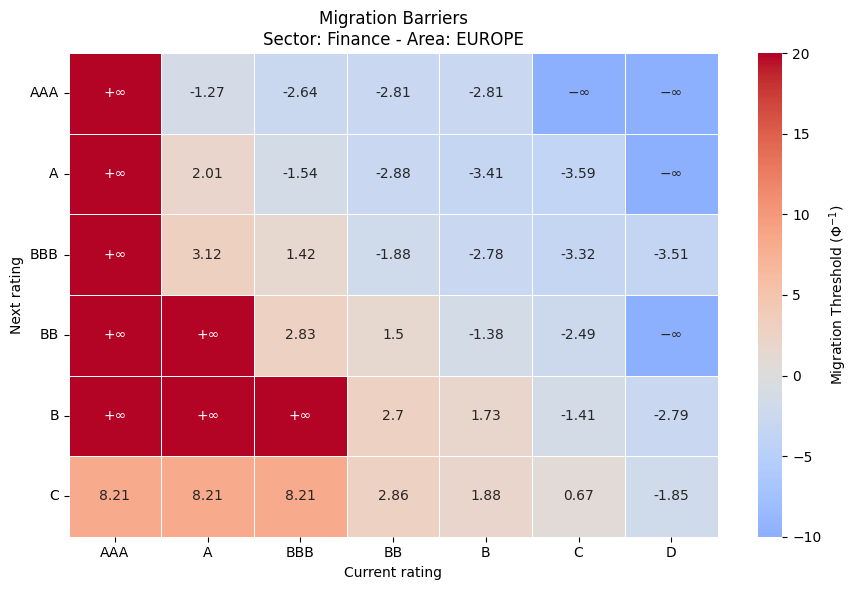

In [49]:
plot_barrier_heatmap_clip(barrier_matrix_df, title="Migration Barriers\nSector: Finance - Area: EUROPE", vmin=-10, vmax=20)

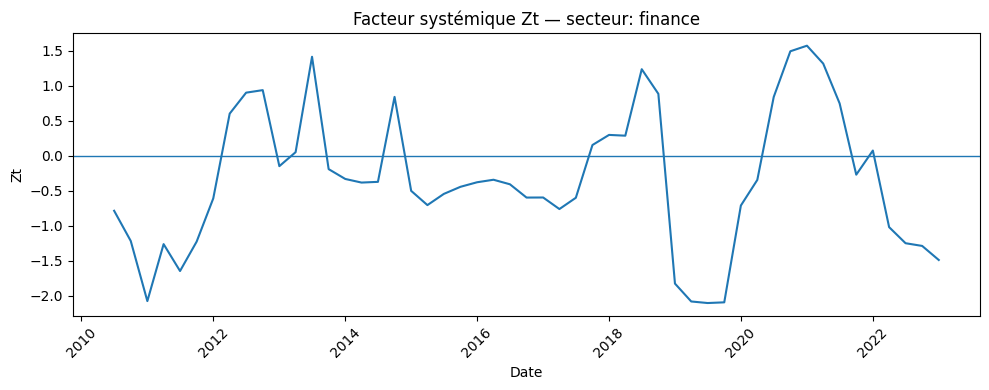

In [50]:
zt_series = optimize_by_sector(df_clean=df_am, date_level="year_quarter", sector_level="sector", sector_value="finance")[0]
def plot_zt_series(zt_series, sector):
    s = zt_series.xs(sector, level="sector").sort_index()

    plt.figure(figsize=(10, 4))
    plt.plot(s.index, s.values)
    plt.axhline(0, linewidth=1)
    plt.title(f"Facteur systémique Zt — secteur: {sector}")
    plt.xlabel("Date")
    plt.ylabel("Zt")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Exemple
plot_zt_series(zt_series, "finance")

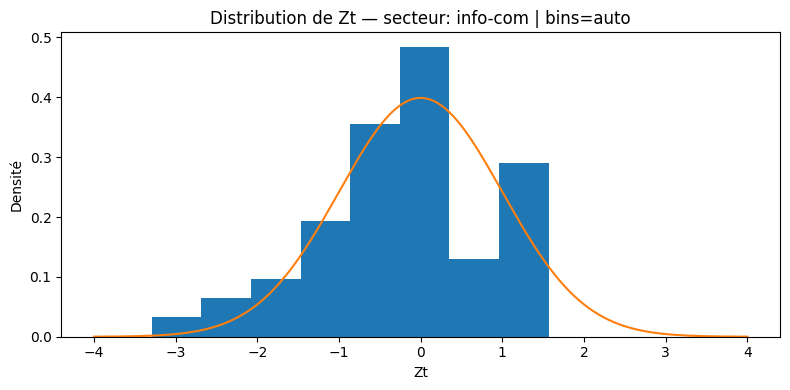

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

def optimal_bins_fd(z):
    """Nombre de bins via Freedman–Diaconis. Retourne un int >= 1."""
    z = np.asarray(z)
    z = z[np.isfinite(z)]
    n = z.size
    if n < 2:
        return 1

    q75, q25 = np.percentile(z, [75, 25])
    iqr = q75 - q25
    if iqr == 0:
        # fallback si données trop concentrées
        return int(np.sqrt(n)) if n > 0 else 1

    bin_width = 2 * iqr * n ** (-1/3)
    if bin_width <= 0:
        return int(np.sqrt(n))

    nbins = int(np.ceil((z.max() - z.min()) / bin_width))
    return max(nbins, 1)

def plot_zt_distribution_hist(zt_series, sector=None, bins="fd"):
    if sector is None:
        z = zt_series.values
        ttl = "Distribution de Zt (tous secteurs)"
    else:
        z = zt_series.values
        #z = zt_series.xs(sector, level="sector").values
        ttl = f"Distribution de Zt — secteur: {sector}"

    z = np.asarray(z)
    z = z[np.isfinite(z)]

    if isinstance(bins, str):
        key = bins.lower()
        if key in ("fd", "freedman-diaconis", "freedman"):
            bins_ = optimal_bins_fd(z)
        elif key in ("sqrt",):
            bins_ = max(int(np.sqrt(len(z))), 1)
        elif key in ("sturges",):
            bins_ = max(int(np.ceil(np.log2(len(z)) + 1)), 1)
        elif key in ("auto",):
            bins_ = "auto"   # délégué à numpy/matplotlib
        else:
            raise ValueError(f"bins='{bins}' inconnu")
    else:
        bins_ = bins  # int, array de bords, etc.

    plt.figure(figsize=(8, 4))
    plt.hist(z, bins=bins_, density=True)
    x = np.linspace(min(z.min(), -4), max(z.max(), 4), 400)
    plt.plot(x, norm.pdf(x, loc=0, scale=1))
    plt.title(ttl + f" | bins={bins_}")
    plt.xlabel("Zt")
    plt.ylabel("Densité")
    plt.tight_layout()
    plt.show()

# Exemple
#plot_zt_distribution_hist(zt_sector, sector="finance", bins="fd")
# ou

plot_zt_distribution_hist(Z_hat_gen[Z_hat_gen["sector"] == "info-com"]["z_t"], sector="info-com", bins="auto")

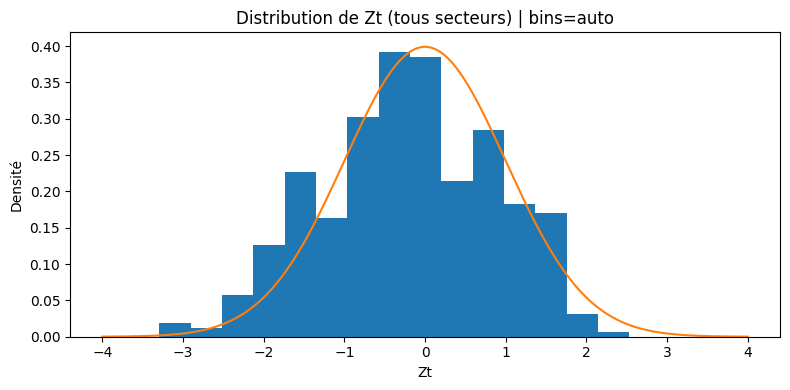

In [52]:
plot_zt_distribution_hist(Z_hat_gen["z_t"], bins="auto")

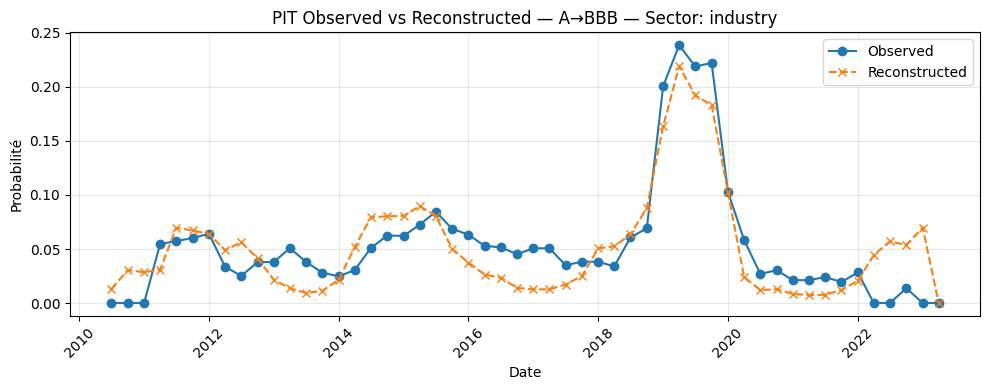

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_pit_observed_vs_reconstructed(probability_migrations, sector, rating="A", next_rating="D"):
    df = probability_migrations.copy()

    # Vérif colonnes
    required_cols = {"observed", "recalculated"}
    if not required_cols.issubset(df.columns):
        raise ValueError(f"Colonnes attendues {required_cols}, colonnes trouvées: {set(df.columns)}")

    # Vérif niveaux index minimaux
    required_levels = {"year_quarter", "rating", "next_rating"}
    if not required_levels.issubset(df.index.names):
        raise ValueError(f"Niveaux attendus au minimum {required_levels}, niveaux trouvés: {df.index.names}")

    # Filtrage sector si présent dans l'index
    if "sector" in df.index.names:
        df = df.xs(sector, level="sector")

    # Filtrage rating et next_rating
    df = df.xs(rating, level="rating")
    df = df.xs(next_rating, level="next_rating")

    # À ce stade, on veut un index temporel simple
    if isinstance(df.index, pd.MultiIndex):
        if "year_quarter" in df.index.names:
            # garder seulement la date
            df = df.reset_index()
            x = pd.to_datetime(df["year_quarter"])
        else:
            raise ValueError(f"Index encore multiple après filtrage: {df.index.names}")
    else:
        x = pd.to_datetime(df.index)

    # Si reset_index a été fait, observed/recalculated sont dans df en colonnes
    y_obs = df["observed"].values
    y_rec = df["recalculated"].values

    # Tri par date
    order = x.argsort()
    x = x.iloc[order] if hasattr(x, "iloc") else x[order]
    y_obs = y_obs[order]
    y_rec = y_rec[order]

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(x, y_obs, marker="o", label="Observed")
    plt.plot(x, y_rec, linestyle="--", marker="x", label="Reconstructed")
    plt.title(f"PIT Observed vs Reconstructed — {rating}→{next_rating} — Sector: industry")
    plt.xlabel("Date")
    plt.ylabel("Probabilité")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Exemple
plot_pit_observed_vs_reconstructed(probs_sector, sector="industrie", rating="A", next_rating="BBB")

In [54]:
y_obs = probs_sector["observed"].values